# 32 — Bayesian extensions: exact-model MCMC, two-detector evidence, calibration of the grid posterior, population inference

**Author:** Giacomo Moretti · *Statistics and Data Analysis*, Università di Milano-Bicocca, A.Y. 2025–2026

**What it does.** Extensions 35, 36, 38 and 54.

* **35. Exact-model parameter estimation.** For the dominant mode a single detector sees Re[C h(f)] with a complex constant C, so with a Gaussian prior on C the likelihood of the *exact* IMRPhenomD model (aligned spins) is analytic and only (M, q, χ₁, χ₂, merger time) remain. They are sampled with `emcee` (ensemble MCMC, 32 walkers; the report of notebook 22 used a non-spinning grid) for 30 injections at ρ = 8, 12, 16: accuracy and coverage, against the grid posterior and the CNN of notebook 22. (`emcee` replaces nested sampling; no `dynesty`/`bilby` is installed.)
* **36. Signal versus glitch with two detectors.** Bayes factors with amplitude marginalisation (σ = 10) of a coherent signal (one complex amplitude, real detector weights integrated over the angle), of a glitch in H1 only or in L1 only, and of independent signals, for physical network injections, blips in a single detector and noise; the odds ln B_C − ln B_G is compared with other statistics as a classifier.
* **38. Calibration of the grid posterior (SBC).** Simulation-based calibration of the (f₀, Q, t₀) posterior of the sine-Gaussian bank in Gaussian noise with data drawn from the generative model, 1 500 simulations, for the 160-template and the 640-template grids; MCMC autocorrelation times of part 35.
* **54. Population inference.** The mass distribution of the pseudo-data population of notebook 19 (peak + flat component) is inferred from the *detected* events with a hierarchical likelihood that includes the selection effect (the response matrix and efficiency of notebook 19), against a naive fit of the reconstructed masses.

**What it does not do.** Single-detector PE (no sky, no precession), MCMC with a moderate number of steps, no nested sampling evidences; the two-detector evidences use the peak-per-template approximation of notebook 31; the SBC is for Gaussian noise (a test of the algorithm, not of the real-noise likelihood); the hyperposterior uses 8 reconstructed masses.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import os, time, pickle
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from concurrent.futures import ProcessPoolExecutor
from scipy import stats
from scipy.special import logsumexp
import imr_tools as it, pe_tools as pe, network_tools as nt, glitch_tools as gt
import gwosc_tools as g
g.style()
rng = np.random.default_rng(32)
CH = {i: g.load_chunk(i) for i in range(len(g.chunks()))}
V, ID = {}, {}
for sp in ("val", "test"): V[sp], ID[sp], _ = g.load_split(sp)
S1te = np.stack([CH[i]["S1"] for i in ID["test"]]); LIB = g.imr_library("test")

## 35. MCMC with the exact IMRPhenomD model

In [2]:
IB = {c: it.IMRBank(CH[c]["S1"]) for c in CH}
def run_set(rho, n=30, seed=0):
    r = np.random.default_rng(1000 * rho + seed); i = r.choice(len(V["test"]), n, replace=False); p = g.draw_params("imr_test", r, n); ser, _, _ = g.inject(V["test"][i], "imr_test", float(rho), r, S1te[i], params=p)
    X = g.to_bins(ser); jobs = []; truth = []
    for a in range(n):
        o = IB[ID["test"][i[a]]].scan(X[a:a + 1]); start = [float(o["f0"][0]), float(o["Q"][0]), 0.0, 0.0, float(o["tau"][0])]
        jobs.append((X[a], S1te[i[a]], None, a, 32, 1500, start)); k = p["lib"][a]
        m1, m2, c1, c2 = LIB["m1"][k], LIB["m2"][k], LIB["chi1"][k], LIB["chi2"][k]; truth.append([LIB["mtot"][k], LIB["q"][k], LIB["mc"][k], (m1 * c1 + m2 * c2) / (m1 + m2), LIB["tc"][k] + p["t0"][a]])
    return jobs, np.array(truth)
fn = os.path.join(g.CACHE, "pe32.pkl")
if os.path.exists(fn): PE = pickle.load(open(fn, "rb"))
else:
    PE = {}; t0_ = time.time()
    with ProcessPoolExecutor(4) as ex:
        for rho in (8, 12, 16):
            jobs, truth = run_set(rho); res = list(ex.map(pe.run_pe, jobs)); PE[rho] = dict(chains=[c for c, _ in res], act=[t for _, t in res], truth=truth); print("rho", rho, "%.0f s" % (time.time() - t0_), flush=True)
    pickle.dump(PE, open(fn, "wb"))
def derived(ch):
    M_, q, c1, c2, tau = ch.T; m1 = M_ / (1 + q); m2 = M_ - m1; return np.column_stack([M_, q, M_ * q ** 0.6 / (1 + q) ** 1.2, (m1 * c1 + m2 * c2) / M_, tau])
NAMES = ["M_tot", "q", "M_chirp", "chi_eff", "t_merge"]; rows = []
for rho, d in PE.items():
    for a, ch in enumerate(d["chains"]):
        D = derived(ch); lo, med, hi = np.percentile(D, [5, 50, 95], axis=0); l68, h68 = np.percentile(D, [16, 84], axis=0); t = d["truth"][a]; tr = [t[0], t[1], t[2], t[3], t[4]]
        for k, nm in enumerate(NAMES): rows.append(dict(rho=rho, sim=a, param=nm, truth=tr[k], median=med[k], err_rel=abs(med[k] - tr[k]) / (abs(tr[k]) if nm != "chi_eff" else 1.0) if nm != "t_merge" else abs(med[k] - tr[k]), in68=bool(l68[k] <= tr[k] <= h68[k]), in90=bool(lo[k] <= tr[k] <= hi[k]), width68=h68[k] - l68[k]))
R35 = pd.DataFrame(rows); print("mean autocorrelation time of the chains (steps):", {rho: round(float(np.nanmean(d["act"])), 1) for rho, d in PE.items()}, "(1500 steps per chain)")
S35 = R35.groupby(["param", "rho"]).agg(median_error=("err_rel", "median"), coverage68=("in68", "mean"), coverage90=("in90", "mean"), median_width68=("width68", "median")); S35.round(3)

mean autocorrelation time of the chains (steps): {8: 116.2, 12: 117.3, 16: 117.4} (1500 steps per chain)


median_error  coverage68  coverage90  median_width68
param   rho                                                      
M_chirp 8           0.047       0.833       0.967           6.753
        12          0.063       0.667       0.833           5.722
        16          0.068       0.700       0.800           3.890
M_tot   8           0.051       0.700       0.967          13.323
        12          0.079       0.633       0.800          12.642
        16          0.053       0.433       0.767           7.713
chi_eff 8           0.129       0.667       0.900           0.356
        12          0.091       0.733       0.900           0.278
        16          0.062       0.700       0.900           0.242
q       8           0.221       0.700       0.867           0.465
        12          0.229       0.700       0.933           0.388
        16          0.276       0.600       0.933           0.368
t_merge 8           0.002       0.533       0.733           0.004
        12          0.001       0.500       0.600           0.003
        16          0.001       0.467       0.600           0.002

## 36. Two detectors: coherent signal against a glitch in one detector

In [3]:
WH = {tag: {d: g.load_coinc_chunk(k, d) for d in ("H1", "L1")} for tag, k in (("o2", 2), ("o5", 5))}
BKN = {(tag, d): it.IMRBank(WH[tag][d]["S1"]) for tag in WH for d in ("H1", "L1")}
z31 = np.load(os.path.join(g.CACHE, "lib31.npz")); LIB31 = {k: z31[k] for k in z31.files}
S2 = 100.0; GATE = 15
def lnbf(r2): return 0.5 * r2 * S2 / (1 + S2) - np.log1p(S2)
TH = np.linspace(0, np.pi, 61)[:-1]
def evidences(tH, zH, tL, zL):
    gate = np.abs(tH.astype(int) - tL.astype(int)) <= GATE; lh, ll = lnbf(np.abs(zH) ** 2), lnbf(np.abs(zL) ** 2)
    lc = np.stack([logsumexp(0.5 * np.abs(np.cos(t) * zH + np.sin(t) * zL) ** 2 * S2 / (1 + S2), axis=None) for t in TH[:1]])    # placeholder, replaced below (vectorised)
    return None
def stats_pairs(pk):
    (tH, zH), (tL, zL) = pk["H1"], pk["L1"]; gate = np.abs(tH.astype(int) - tL.astype(int)) <= GATE
    lh, ll = lnbf(np.abs(zH) ** 2), lnbf(np.abs(zL) ** 2)
    ang = 0.5 * np.abs(np.cos(TH)[None, None, :] * zH[..., None] + np.sin(TH)[None, None, :] * zL[..., None]) ** 2 * S2 / (1 + S2)
    lc = logsumexp(ang, axis=-1) - np.log(len(TH)) - np.log1p(S2)
    lg = np.logaddexp(lh, ll) - np.log(2)
    NEG = -1e9
    out = {"ln B_C - ln B_G (evidence odds)": np.where(gate, lc - lg, NEG).max(1), "ln B_C (coherent)": np.where(gate, lc, NEG).max(1), "ln B_I (independent)": np.where(gate, lh + ll, NEG).max(1),
           "rho_net^2 (same template)": np.where(gate, np.abs(zH) ** 2 + np.abs(zL) ** 2, 0).max(1), "min(rho_H^2, rho_L^2)": np.where(gate, np.minimum(np.abs(zH) ** 2, np.abs(zL) ** 2), 0).max(1)}
    return out
def make_pairs(kind, norm, n, r):
    tags = r.choice(list(WH), n); idx = np.array([r.integers(0, len(WH[t]["H1"]["v"])) for t in tags]); j = r.integers(0, len(LIB31["Hp"]), n); out = {"H1": [], "L1": []}; pk = {"H1": [None] * 0, "L1": []}
    res = {d: (np.zeros((n, 24), np.int16), np.zeros((n, 24), np.complex64)) for d in ("H1", "L1")}
    for t in WH:
        m = tags == t
        if not m.any(): continue
        Wv = {d: WH[t][d]["v"][idx[m]] for d in ("H1", "L1")}; S1 = {d: np.repeat(WH[t][d]["S1"][None], m.sum(), 0) for d in ("H1", "L1")}
        if kind == "signal": ser = nt.network_signal(Wv, S1, LIB31, j[m], norm, r)
        elif kind == "glitch_H1": ser = nt.network_signal(Wv, S1, LIB31, j[m], norm, r, glitch="H1")
        elif kind == "glitch_L1": ser = nt.network_signal(Wv, S1, LIB31, j[m], norm, r, glitch="L1")
        else: ser = Wv
        for d in ("H1", "L1"):
            a, b = nt.peaks(BKN[(t, d)], g.to_bins(ser[d])); res[d][0][m], res[d][1][m] = a, b
    return stats_pairs(res)
fn = os.path.join(g.CACHE, "stats32_two.pkl")
if os.path.exists(fn): TWO = pickle.load(open(fn, "rb"))
else:
    TWO = {}; r = np.random.default_rng(36)
    for kind in ("signal", "glitch_H1", "glitch_L1"):
        for norm in (6, 8, 10, 12): TWO[(kind, norm)] = make_pairs(kind, float(norm), 400, r)
    TWO["noise"] = make_pairs("noise", 0.0, 3000, r); pickle.dump(TWO, open(fn, "wb"))
from sklearn.metrics import roc_auc_score
rows = []
for norm in (6, 8, 10, 12):
    for k in TWO["noise"]:
        gl = np.concatenate([TWO[("glitch_H1", norm)][k], TWO[("glitch_L1", norm)][k]]); sg = TWO[("signal", norm)][k]
        rows.append(dict(norm=norm, statistic=k, AUC_signal_vs_glitch=roc_auc_score(np.r_[np.ones(len(sg)), np.zeros(len(gl))], np.r_[sg, gl])))
AUC = pd.DataFrame(rows).pivot_table(index="statistic", columns="norm", values="AUC_signal_vs_glitch"); print("AUC of signal (network injection) against a blip in one detector, same network norm:"); display(AUC.round(3))
od = TWO["noise"]["ln B_C - ln B_G (evidence odds)"]; print("noise windows with ln B_C - ln B_G > ln 100: %.4f; with ln B_C > ln 100: %.4f" % ((od > np.log(100)).mean(), (TWO["noise"]["ln B_C (coherent)"] > np.log(100)).mean()))

AUC of signal (network injection) against a blip in one detector, same network norm:


norm,6,8,10,12
statistic,,,,
ln B_C (coherent),0.735,0.862,0.911,0.925
ln B_C - ln B_G (evidence odds),0.717,0.851,0.912,0.934
ln B_I (independent),0.741,0.866,0.912,0.925
"min(rho_H^2, rho_L^2)",0.742,0.872,0.920,0.937
rho_net^2 (same template),0.741,0.866,0.912,0.925


noise windows with ln B_C - ln B_G > ln 100: 0.0807; with ln B_C > ln 100: 0.3180


## 38. Simulation-based calibration of the grid posterior

In [4]:
S1c = CH[3]["S1"]; s_amp = 10.0
def sbc(nf, nq, nsim=1500, seed=0):
    r = np.random.default_rng(seed); bank = g.SGBank(S1c, f0s=np.geomspace(40, 450, nf), Qs=np.geomspace(3, 16, nq)); f_edges = np.sqrt(bank.f0s[1:] * bank.f0s[:-1]); Qs = bank.Qs; U = {"f0": [], "Q": [], "tau": []}
    tau_grid = np.arange(int(0.15 * g.NWIN), int(0.85 * g.NWIN)) / g.NWIN
    for a in range(0, nsim, 50):
        n = min(50, nsim - a); f0 = np.exp(r.uniform(np.log(40), np.log(450), n)); Q = r.uniform(3, 16, n); tau = r.uniform(0.3, 0.7, n)
        T = 2.0 * g.sine_gaussian_ft(g.FREQ[None, :], f0[:, None], Q[:, None], 0.0, positive_only=True) / np.sqrt(S1c)[None, :] * g.BAND; T = T / np.sqrt(np.sum(np.abs(T) ** 2, axis=1))[:, None]
        A = s_amp * (r.normal(size=n) + 1j * r.normal(size=n)); noise = (r.normal(size=(n, g.NB)) + 1j * r.normal(size=(n, g.NB))) * g.BAND
        X = noise + A[:, None] * T * np.exp(-2j * np.pi * g.FREQ[None, :] * tau[:, None]); o = bank.scan(X, return_cube=True); cube = o["cube"].astype(np.float64)       # (n, nT, ntau)
        lnl = 0.5 * cube * s_amp ** 2 / (1 + s_amp ** 2); lt = logsumexp(lnl, axis=2); lt -= logsumexp(lt, axis=1, keepdims=True); pt_ = np.exp(lt).reshape(n, nq, nf)       # SGBank grid order: for q: for f
        ltau = logsumexp(lnl, axis=1); ltau -= logsumexp(ltau, axis=1, keepdims=True); ptau = np.exp(ltau)
        for b in range(n):
            pf = pt_[b].sum(0); idx = np.searchsorted(f_edges, f0[b]); cdf = np.cumsum(pf) - pf; lo = np.r_[bank.f0s[0] * 0.8, f_edges][idx]; hi = np.r_[f_edges, bank.f0s[-1] * 1.2][idx]; U["f0"].append(cdf[idx] + pf[idx] * (np.log(f0[b]) - np.log(lo)) / (np.log(hi) - np.log(lo)))
            pq = pt_[b].sum(1); qe = np.sqrt(Qs[1:] * Qs[:-1]); idq = np.searchsorted(qe, Q[b]); cdq = np.cumsum(pq) - pq; lq = np.r_[3.0, qe][idq]; hq = np.r_[qe, 16.0][idq]; U["Q"].append(cdq[idq] + pq[idq] * (Q[b] - lq) / (hq - lq))
            cdt = np.cumsum(ptau[b]); i = np.searchsorted(tau_grid, tau[b]); U["tau"].append(np.clip(cdt[min(i, len(cdt) - 1)] - ptau[b][min(i, len(cdt) - 1)] * 0.5, 0, 1))
    return {k: np.array(v) for k, v in U.items()}
fn = os.path.join(g.CACHE, "sbc32.pkl")
if os.path.exists(fn): SB = pickle.load(open(fn, "rb"))
else: SB = {"160 templates (40x4)": sbc(40, 4, seed=1), "640 templates (80x8)": sbc(80, 8, seed=2)}; pickle.dump(SB, open(fn, "wb"))
rows = [dict(grid=gname, param=k, KS_p=float(stats.kstest(u, "uniform").pvalue), KS_stat=float(stats.kstest(u, "uniform").statistic), frac_in_central68=float(((u > 0.16) & (u < 0.84)).mean()), mean=float(u.mean())) for gname, d in SB.items() for k, u in d.items()]
SBC = pd.DataFrame(rows); SBC.round(3)

,grid,param,KS_p,KS_stat,frac_in_central68,mean
0,160 templates (40x4),f0,0.001,0.050,0.711,0.520
1,160 templates (40x4),Q,0.000,0.061,0.715,0.533
2,160 templates (40x4),tau,0.000,0.183,0.662,0.613
3,640 templates (80x8),f0,0.000,0.060,0.743,0.511
4,640 templates (80x8),Q,0.000,0.061,0.731,0.524
5,640 templates (80x8),tau,0.000,0.162,0.668,0.605


## 54. Hierarchical inference of the mass distribution with selection effects

In [5]:
z = np.load(os.path.join(g.CACHE, "unfold19.npz"), allow_pickle=True); SIM, DAT = z["SIM"].item(), z["DAT"].item()
EDG = np.linspace(30, 100, 15); K = len(EDG) - 1; MC = 0.5 * (EDG[1:] + EDG[:-1]); MR = np.sort(np.unique(SIM["reco"][:, 0])); NR = len(MR)
tb = np.clip(np.digitize(SIM["truth"][:, 0], EDG[1:-1]), 0, K - 1); rb = np.searchsorted(MR, SIM["reco"][:, 0])
RESP = np.zeros((NR, K))
for k in range(K):
    m = (tb == k) & SIM["passed"]; RESP[:, k] = np.bincount(rb[m], minlength=NR) / max((tb == k).sum(), 1)
ALPHA = RESP.sum(0); det_idx = np.searchsorted(MR, DAT["reco"][DAT["passed"], 0]); NDET = len(det_idx)
def prior_bins(mu, sig, f):
    gcomp = stats.norm.cdf(EDG[1:], mu, sig) - stats.norm.cdf(EDG[:-1], mu, sig); gcomp = gcomp / gcomp.sum(); return f * np.full(K, 1.0 / K) + (1 - f) * gcomp
RBIN = np.clip(np.digitize(MR, EDG[1:-1]), 0, K - 1)           # truth bin containing each reconstructed template mass (naive treatment)
def loglike(mu, sig, f, proper=True):
    p = prior_bins(mu, sig, f)
    if proper:      # response + selection: P(reco index | Lambda, detected) = sum_k RESP[i,k] p_k / sum_k alpha_k p_k
        num = (RESP * p[None, :]).sum(1); return float(np.sum(np.log(np.maximum(num[det_idx], 1e-300))) - NDET * np.log((p * ALPHA).sum()))
    pn = p[RBIN] / np.sum(p[RBIN]); return float(np.sum(np.log(np.maximum(pn[det_idx], 1e-300))))          # naive: reconstructed mass taken as the true one, no efficiency
MUS, SIGS, FS = np.linspace(38, 52, 57), np.linspace(2, 12, 41), np.linspace(0.05, 0.8, 31)
LL = {sel: np.array([[[loglike(m, s, f, sel) for f in FS] for s in SIGS] for m in MUS]) for sel in (True, False)}
def summarize(L):
    P = np.exp(L - L.max()); P /= P.sum(); out = {}
    for nm, ax, grid in (("mu", (1, 2), MUS), ("sigma", (0, 2), SIGS), ("f_flat", (0, 1), FS)):
        marg = P.sum(axis=ax); c = np.cumsum(marg); out[nm] = (float(grid @ marg), float(np.interp(0.16, c, grid)), float(np.interp(0.84, c, grid)))
    return out
HP = {("response + selection effects" if k else "naive (reconstructed = true, no efficiency)"): summarize(v) for k, v in LL.items()}
tr = DAT["truth"][:, 0]; ptrue_best = max(((loglike_t := np.sum(np.log(prior_bins(m, s, f)[np.clip(np.digitize(tr, EDG[1:-1]), 0, K - 1)] )) ), (m, s, f)) for m in MUS[::2] for s in SIGS[::2] for f in FS[::2])
print("maximum-likelihood fit of the TRUE (all, undetected included) masses: mu=%.1f sigma=%.1f f_flat=%.2f" % ptrue_best[1])
pd.DataFrame(HP).T.round(2)

maximum-likelihood fit of the TRUE (all, undetected included) masses: mu=45.0 sigma=5.0 f_flat=0.30


,mu,sigma,f_flat
response + selection effects,"(44.79058742260458, 44.545636990551984, 44.769...","(4.716895734654642, 4.45634231710304, 4.716893...","(0.29791771518367394, 0.2770856028053108, 0.29..."
"naive (reconstructed = true, no efficiency)","(49.58341976558015, 49.30329476665927, 49.6403...","(6.447465438732926, 6.1823374838549885, 6.4511...","(0.3640495437899922, 0.3341289009213163, 0.367..."


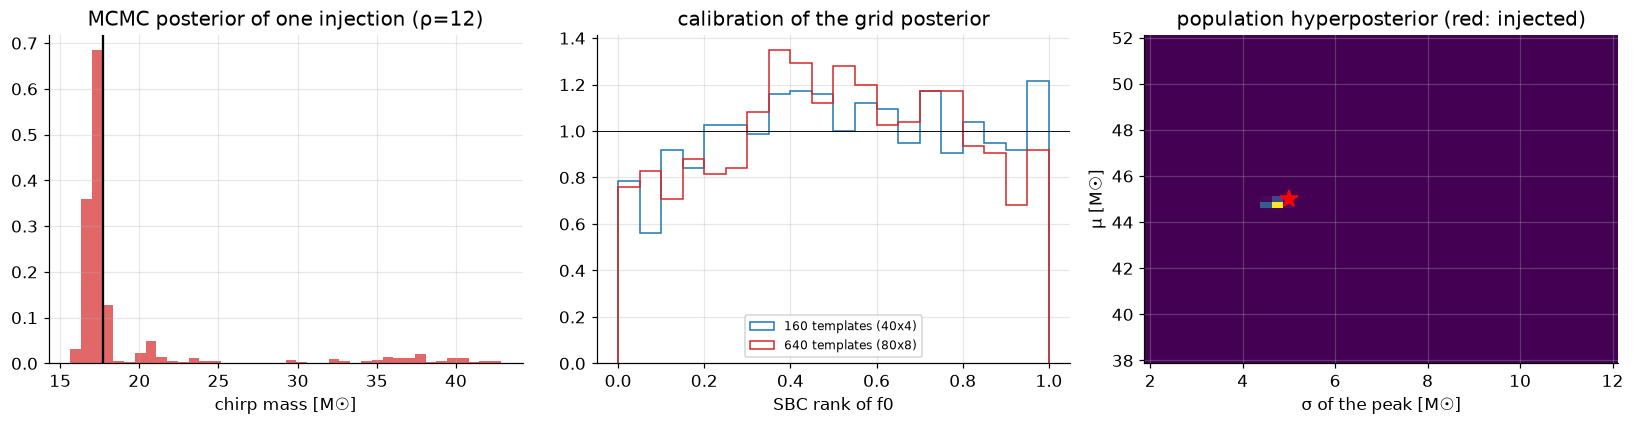

saved


In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
rho = 12; d = PE[rho]; D = derived(d["chains"][0]); ax[0].hist(D[:, 2], bins=40, color=g.COLORS["bayes"], alpha=.7, density=True); ax[0].axvline(d["truth"][0][2], color="k"); ax[0].set_xlabel("chirp mass [M☉]"); ax[0].set_title("MCMC posterior of one injection (ρ=12)")
for gname, c in (("160 templates (40x4)", "C0"), ("640 templates (80x8)", "C3")): ax[1].hist(SB[gname]["f0"], bins=20, histtype="step", color=c, density=True, label=gname)
ax[1].axhline(1, color="k", lw=.6); ax[1].set_xlabel("SBC rank of f0"); ax[1].legend(fontsize=8); ax[1].set_title("calibration of the grid posterior")
P = np.exp(LL[True] - LL[True].max()); P /= P.sum(); ax[2].pcolormesh(SIGS, MUS, P.sum(2), cmap="viridis"); ax[2].plot([5], [45], "r*", ms=12); ax[2].set_xlabel("σ of the peak [M☉]"); ax[2].set_ylabel("μ [M☉]"); ax[2].set_title("population hyperposterior (red: injected)")
fig.tight_layout(); g.savefig(fig, "fig32_bayes_extensions"); plt.show()
g.save_json(dict(pe=S35.reset_index().to_dict("records"), act={str(k): float(np.nanmean(d["act"])) for k, d in PE.items()}, two_detector_auc=AUC.reset_index().to_dict("records"), noise_B100_odds=float((od > np.log(100)).mean()),
                 sbc=SBC.to_dict("records"), population={k: v for k, v in HP.items()}, population_truth_fit=list(map(float, ptrue_best[1]))), "32_summary.json"); print("saved")

## Output and next step

`results/32_summary.json`, `figures/fig32_bayes_extensions`, `pe_tools.py`, `network_tools.py`. Next: the heavy machine-learning variants (2-D CNN, ResNet, Transformer tuning) and the unsupervised noise models.